# **Trabalho - Inteligência Artificial**

Vamos começar importanto as bibliotecas que serão utilizadas:

In [1]:
# Bibliotecas:
import matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from sklearn.datasets import load_breast_cancer, fetch_openml

# Frameworks de treinamento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Modelos de ML:
from sklearn.naive_bayes import GaussianNB

# Matriz e métricas:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

As bases de dados que serão utilizadas são: Breast Cancer e Mnsit.

## **1.) Breast Cancer**

### **Etapa 1.) Entender a base de dados, e aplicar o modelo, fazendo a 1ª rodada de métricas**

Vamos observar como a base de dados "Breast Cancer" está organizada:

In [2]:
df0 = pd.read_csv("C:/Users/vtrev/Desktop/Trabalho_IA/data/breast_cancer/breast_cancer_winsconsin.csv")

print(df0.head())
print()
print(df0.shape)

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

Também podemos usar o sklearn.datasets para importar as bibliotecas diretamente como objetos, a fim de operarmos sobre eles:

In [3]:
from sklearn.datasets import load_breast_cancer

breast_cancer = load_breast_cancer()

X_bc = breast_cancer.data
y_bc = breast_cancer.target

print("Formato dos dados:", X_bc.shape)
print("Formato dos rótulos:", y_bc.shape)

print("Classes:", breast_cancer.target_names)

Formato dos dados: (569, 30)
Formato dos rótulos: (569,)
Classes: ['malignant' 'benign']


---

Agora, vamos operar com a base de dados do csv, posteriormente, veremos como operar com os objetos em si.

In [4]:
# Vamos ver quantas classificações existem entre as 2 classes:
print(df0["diagnosis"].value_counts())
print()
# Agora, vamos remover as colunas que estão vazias no csv:
df = df0.drop(columns=["id", "Unnamed: 32"])
# Se checarmos com "print(df.isnull().sum())", vemos que não há mais nenhuma coluna vazia

print(df.shape)
print()

# Agora, vamos separar 
# X: características utilizadas pelo algoritmo;
# Y: respostas corretas que queremos que ele aprenda a prever.

X = df.drop(columns=["diagnosis"]) # coluna com os valores X de entrada
y = df["diagnosis"] # coluna com os valores já previstos

# Agora, vamos separar os dados para teste e treinamento:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# 6. Conferir os resultados
print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)
print()

print("Classes no treinamento:")
print(pd.Series(y_train).value_counts())
print()

print("Classes no teste:")
print(pd.Series(y_test).value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64

(569, 31)



Treinamento: (455, 30)
Teste: (114, 30)

Classes no treinamento:
diagnosis
B    285
M    170
Name: count, dtype: int64

Classes no teste:
diagnosis
B    72
M    42
Name: count, dtype: int64


Agora, vamos aplicar o modelo do Naive-Bayes:

In [5]:
# Criando o modelo:
modelo_nb = GaussianNB()

# Treinando com as linhas de treinamento escolhidas:
modelo_nb.fit(X_train, y_train)

# Fazer previsões com os dados de teste:
y_pred_nb = modelo_nb.predict(X_test)

# Conferir algumas previsões dos valores de teste (10 primeiros):
print("Previsões:", y_pred_nb[:10])
print("Valores reais:", y_test[:10].values)

Previsões: ['B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B']
Valores reais: ['B' 'M' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B']


Agora, vamos avaliar construir a matriz de confusão:

[[72  0]
 [ 7 35]]


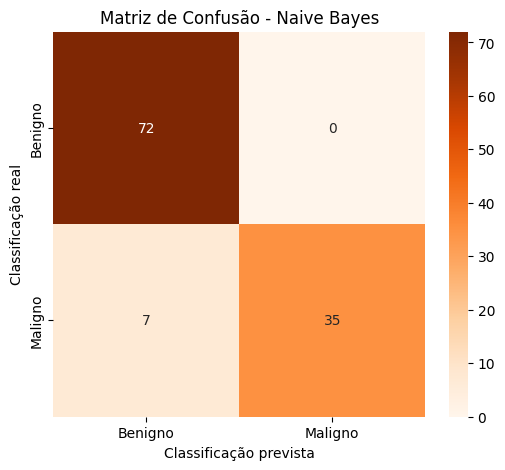

In [6]:
# Calculando a matriz de confusão:
matriz_nb = confusion_matrix(y_test, y_pred_nb, labels=["B", "M"])

# Printando a matriz sem design:
print(matriz_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(matriz_nb, annot=True, fmt="d", cmap="Oranges", xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])

plt.xlabel("Classificação prevista")
plt.ylabel("Classificação real")
plt.title("Matriz de Confusão - Naive Bayes")

plt.show()

Agora, vamos calcular as métricas, considerando:
Classe positiva -> M (maligno) e
Classe negativa -> B (benigno):

In [7]:
# Accuracy
acc_nb = accuracy_score(y_test, y_pred_nb)
acc_nb *= 100

# Precision da classe M
prec_nb = precision_score(y_test, y_pred_nb, pos_label="M")
prec_nb *= 100
# Recall da classe M
rec_nb = recall_score(y_test, y_pred_nb, pos_label="M")
rec_nb *= 100
# F1-score da classe M
f1_nb = f1_score(y_test, y_pred_nb, pos_label="M")
f1_nb *= 100
print("Resultados - Naive Bayes:")
print(f"Accuracy:  {acc_nb:.2f}%")
print(f"Precision: {prec_nb:.2f}%")
print(f"Recall:    {rec_nb:.2f}%")
print(f"F1-score:  {f1_nb:.2f}%")

Resultados - Naive Bayes:
Accuracy:  93.86%
Precision: 100.00%
Recall:    83.33%
F1-score:  90.91%


## **Etapa 2.) Segunda rodada das métricas:**

Agora, vamos fazer uma segunda rodada, ajustando parâmetros do Naive-Bayes:

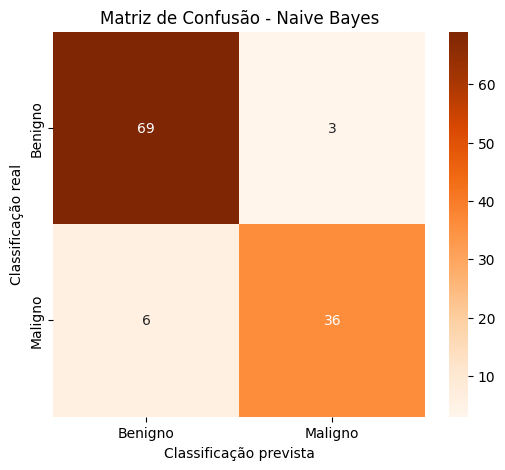

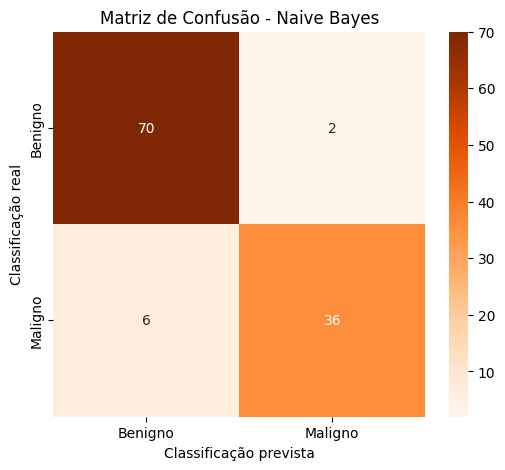

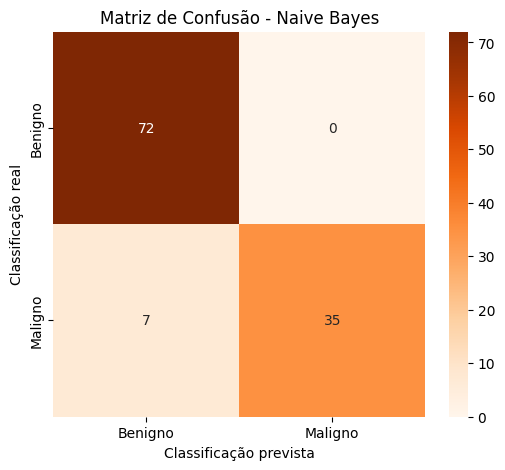

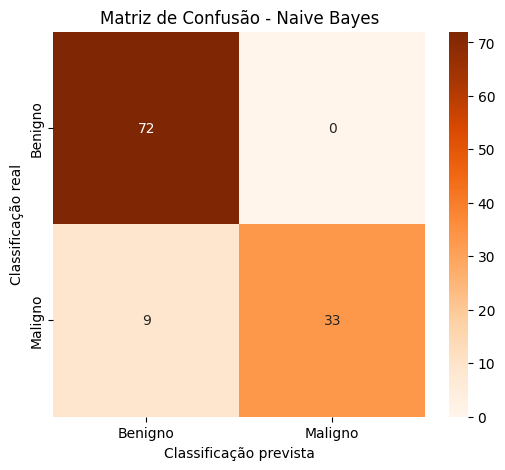

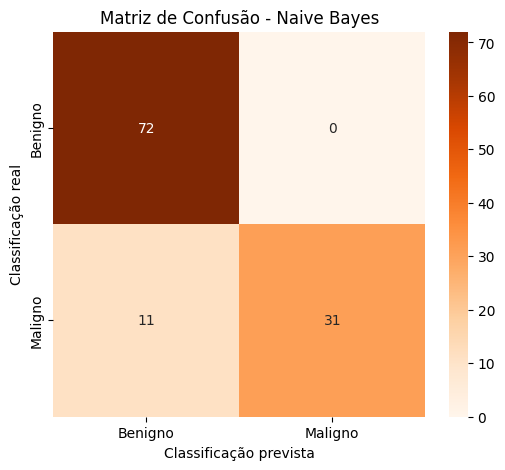

,var_smoothing,Accuracy,Precision,Recall,F1-score
0,1.000000e-12,92.105263,92.307692,85.714286,88.888889
1,1.000000e-10,92.982456,94.736842,85.714286,90.000000
2,1.000000e-09,93.859649,100.000000,83.333333,90.909091
3,1.000000e-08,92.105263,100.000000,78.571429,88.000000
4,1.000000e-06,90.350877,100.000000,73.809524,84.931507


In [8]:
valores = [1e-12, 1e-10, 1e-9, 1e-8, 1e-6]

resultados_nb = []

for valor in valores:
    modelo = GaussianNB(var_smoothing=valor)
    modelo.fit(X_train, y_train)
    previsoes = modelo.predict(X_test)
    matriz_nb = confusion_matrix(y_test, previsoes, labels=["B", "M"])

    plt.figure(figsize=(6, 5))
    sns.heatmap(matriz_nb, annot=True, fmt="d", cmap="Oranges", xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"])
    plt.xlabel("Classificação prevista")
    plt.ylabel("Classificação real")
    plt.title("Matriz de Confusão - Naive Bayes")
    plt.show() 
    
    resultados_nb.append({
        "var_smoothing": valor,
        "Accuracy": accuracy_score(y_test, previsoes) *100,
        "Precision": precision_score(y_test, previsoes, pos_label="M")*100,
        "Recall": recall_score(y_test, previsoes, pos_label="M")*100,
        "F1-score": f1_score(y_test, previsoes, pos_label="M")*100
    })

df_resultados_nb = pd.DataFrame(resultados_nb)

display(df_resultados_nb)

---

## **Mnist**

### **Etapa 1.) Entender a base de dados, e aplicar o modelo, fazendo a 1ª rodada de métricas**

In [9]:
df1 = pd.read_csv("C:/Users/vtrev/Desktop/Trabalho_IA/data/mnist/train.csv")

print(df1.shape)
print(df1.head())
print(df1["label"].value_counts().sort_index())

# Verificando se tem valores ausentes: print(df0.isnull().sum().sum())

(42000, 785)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0         0      

In [10]:
# Vamos ver quantas classificações existem entre as 2 classes:
print(df1["label"].value_counts())
print()

print(df1.shape)
print()

# Agora, vamos separar 
# X: características utilizadas pelo algoritmo;
# Y: respostas corretas que queremos que ele aprenda a prever.

Xm = df1.drop(columns=["label"]) # coluna com os valores X de entrada
ym = df1["label"] # coluna com os valores já previstos

# Agora, vamos separar os dados para teste e treinamento:
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm,ym,test_size=0.2,random_state=42,stratify=ym)

# 6. Conferir os resultados
print("Treinamento:", Xm_train.shape)
print("Teste:", Xm_test.shape)
print()

print("Classes no treinamento:")
print(pd.Series(ym_train).value_counts())
print()

print("Classes no teste:")
print(pd.Series(ym_test).value_counts())

label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64

(42000, 785)



Treinamento: (33600, 784)
Teste: (8400, 784)

Classes no treinamento:
label
1    3747
7    3521
3    3481
9    3350
2    3342
6    3310
0    3305
4    3258
8    3250
5    3036
Name: count, dtype: int64

Classes no teste:
label
1    937
7    880
3    870
9    838
2    835
0    827
6    827
4    814
8    813
5    759
Name: count, dtype: int64


---